# Plots

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tifffile
import pandas as pd
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

## Microscope - imaging testing

In [2]:
# Read images
im_b = tifffile.imread("Microscope/GFP_02092026_BF.tif")
im_fluo_first_frame = tifffile.imread("Microscope/GFP_02092026_fluo70P_NDTiffStack-slice1.tif", key=slice(None))

# Apply contrast
p2_fl, p98_fl = np.percentile(im_fluo_first_frame, (0.01, 99.99))
im_fluo_contrast = np.clip(im_fluo_first_frame, p2_fl, p98_fl)
im_fluo_contrast = (im_fluo_contrast - p2_fl) / (p98_fl - p2_fl + 1e-5)

p2_fl, p98_fl = np.percentile(im_fluo_first_frame, (0.12, 99.88))
im_b_contrast = np.clip(im_b, p2_fl, p98_fl)
im_b_contrast = (im_b_contrast - p2_fl) / (p98_fl - p2_fl + 1e-5)

<Figure size 750x250 with 0 Axes>

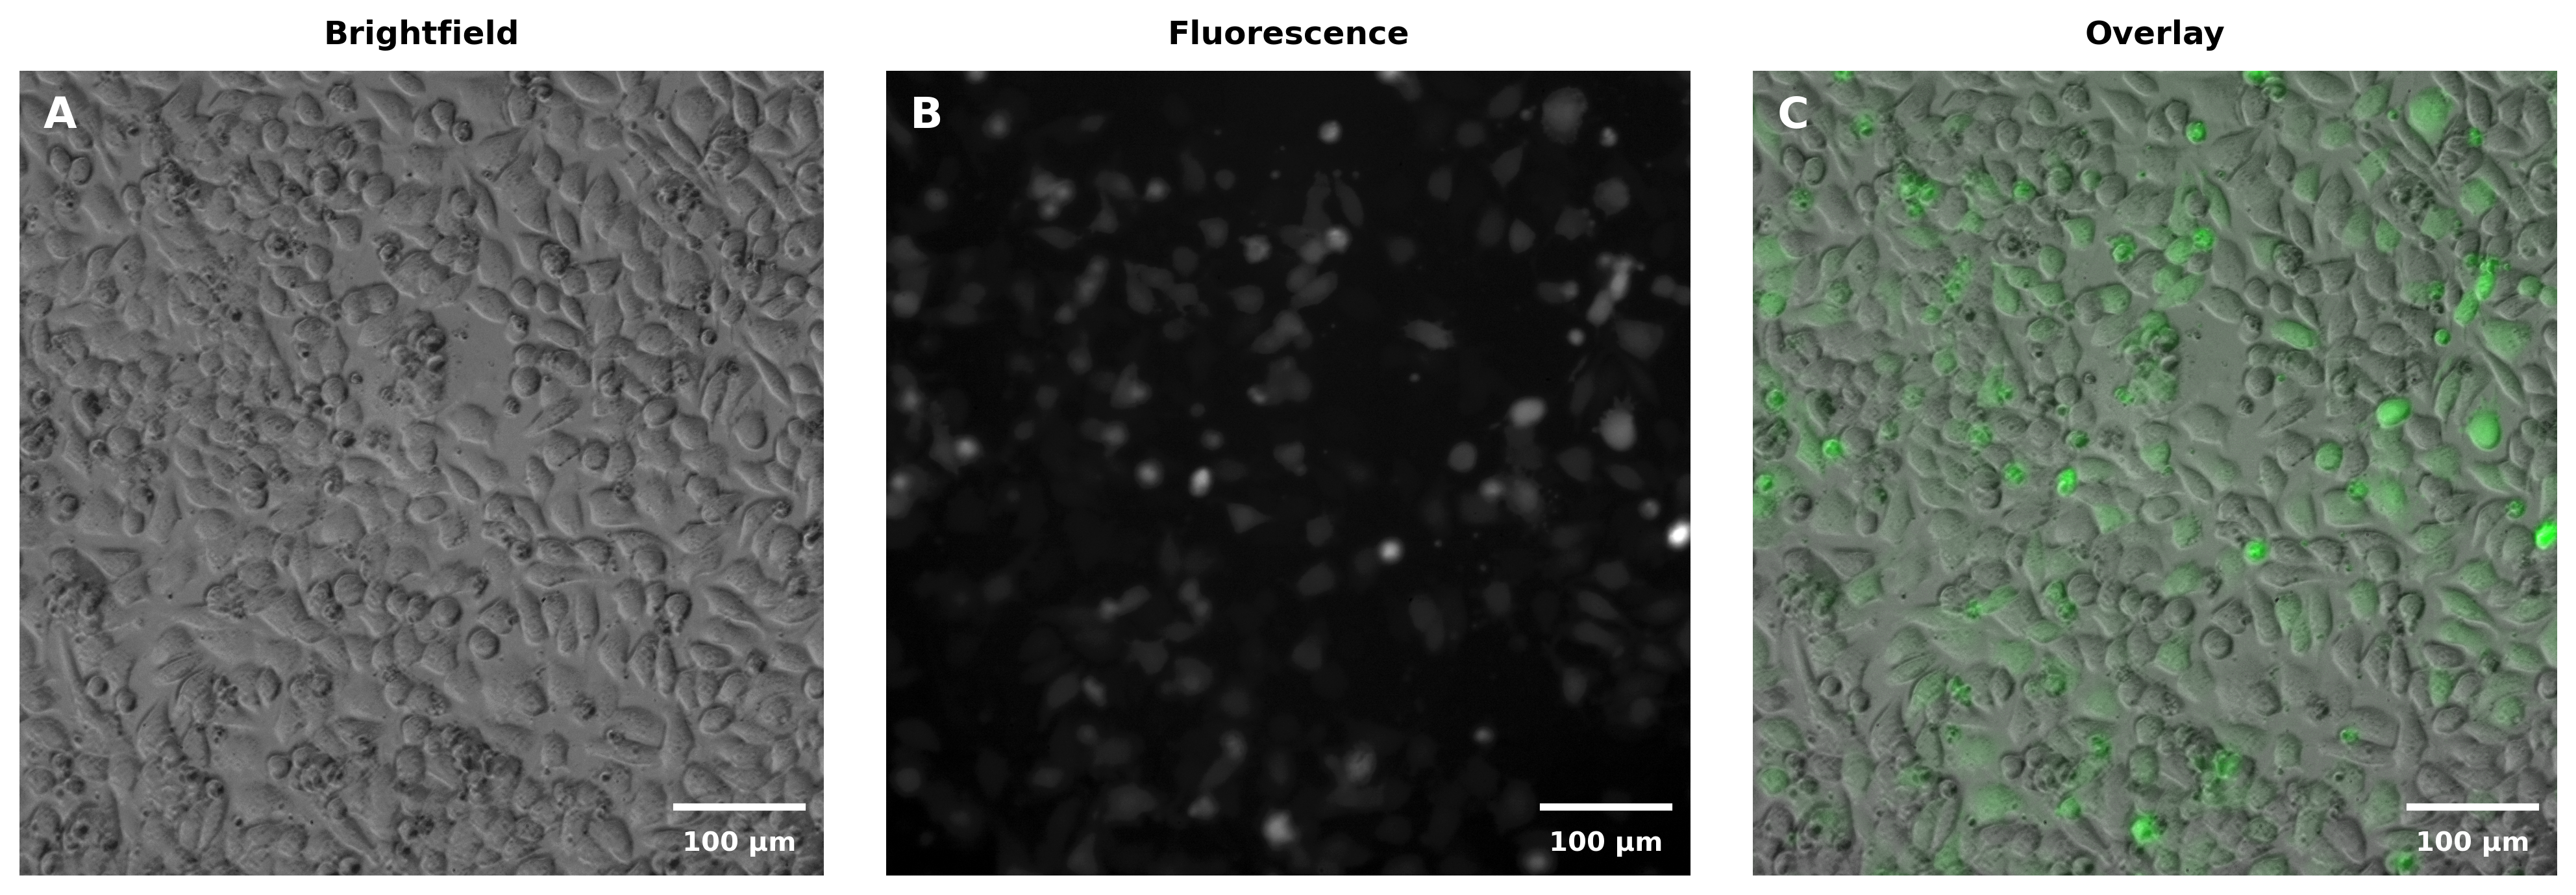

In [3]:
# RGB Green Overlay
# Normalize images to [0, 1] range for clean intensity mapping
b_norm = im_b_contrast.astype(float) / np.max(im_b_contrast)
f_norm = im_fluo_contrast.astype(float) / np.max(im_fluo_contrast)

# Create an RGB image: BF in all 3 channels + Green added to the Green channel
overlay_rgb = np.zeros((*b_norm.shape, 3))
overlay_rgb[:, :, 0] = b_norm  # Red
overlay_rgb[:, :, 1] = np.clip(b_norm + f_norm, 0, 1)  # Green (BF + Fluo)
overlay_rgb[:, :, 2] = b_norm  # Blue

# Scale Bar Parameters
pixel_size_um = 2.74 / 20 # 1 px = 2.74 µm, 20x objective
target_length_um = 100  # Scale bar size in µm
size_in_pixels = target_length_um / pixel_size_um

plt.figure(figsize=(7.5, 2.5))

plt.style.use("default")
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(13.5, 4.5), dpi=300)

ax[0].imshow(im_b_contrast, cmap="gray")
ax[0].set_title("Brightfield", fontsize=12, pad=10, fontweight="bold")

ax[1].imshow(im_fluo_contrast, cmap="gray")
ax[1].set_title("Fluorescence", fontsize=12, pad=10, fontweight="bold")

ax[2].imshow(overlay_rgb)
ax[2].set_title("Overlay", fontsize=12, pad=10, fontweight="bold")

# Add Scalebars & Formatting
for i, a in enumerate(ax):
    a.axis("off")

    scalebar = AnchoredSizeBar(
        a.transData,
        size_in_pixels,
        rf"{target_length_um} µm",
        loc="lower right",
        pad=0.6,
        sep=8,
        color="white",
        frameon=False,
        size_vertical=25,
        fontproperties={"size": 10, "weight": "bold"},
    )
    a.add_artist(scalebar)

    # Add Figure Panel Labels (A, B, C)
    a.text(
        0.03,
        0.97,
        chr(65 + i),
        transform=a.transAxes,
        fontsize=16,
        fontweight="bold",
        color="white",
        va="top",
        ha="left",
    )

plt.savefig("imaging_tests.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

## Benchmarking

### Flow-Rate Optimization

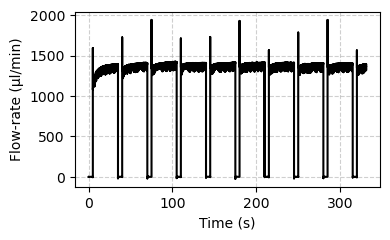

In [4]:
df = pd.read_csv("Calibration_Benchmarking/Flow_Rate_Optimization/flow_rate_nrreservoirs_5_30s.csv")
df["Time"] = pd.to_datetime(df["Time"])
df["Delta_T"] = (df["Time"] - df["Time"].iloc[0]).dt.total_seconds()

plt.figure(figsize=(4, 2.5))
plt.plot(df["Delta_T"], df["Flow-rate [ul/min]"], color="black",)
plt.xlabel("Time (s)")
plt.ylabel("Flow-rate (µl/min)")
plt.grid(True, linestyle="--", alpha=0.6)

#plt.savefig(r"oscillations.png", dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

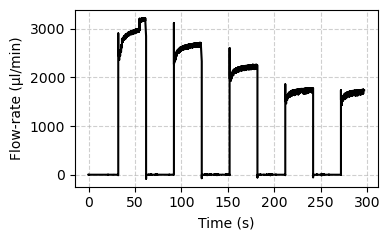

In [16]:
df = pd.read_csv("Calibration_Benchmarking/Flow_Rate_Optimization/flow_rate_nrreservoirs_vary_30s.csv")
df["Time"] = pd.to_datetime(df["Time"])
df["Delta_T"] = (df["Time"] - df["Time"].iloc[0]).dt.total_seconds()

plt.figure(figsize=(4, 2.5))
plt.plot(df["Delta_T"], df["Flow-rate [ul/min]"], color="black",)
plt.xlabel("Time (s)")
plt.ylabel("Flow-rate (µl/min)")
plt.grid(True, linestyle="--", alpha=0.6)

#plt.savefig(r"vary.png", dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

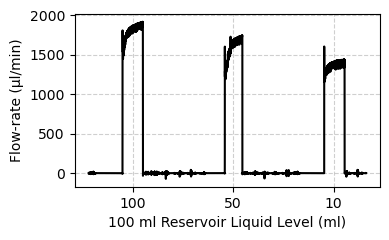

In [17]:
df = pd.read_csv("Calibration_Benchmarking/Flow_Rate_Optimization/flow_rate_nrreservoirs_fillness_30s.csv")

plt.figure(figsize=(4, 2.5))
plt.plot(df["Time"], df["Flow-rate [ul/min]"], color="black",)

# Custom ticks
plt.xticks(
    [1250, 4070, 6900],
    ['100', '50', '10']
)

plt.xlabel("100 ml Reservoir Liquid Level (ml)")
plt.ylabel("Flow-rate (µl/min)")
plt.grid(True, linestyle="--", alpha=0.6)
#plt.savefig("fluid_level.png", dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

### Correct Volume Dispensing

In [7]:
results_by_volume = {1000:
                         [1.0, 1.04, 1.03, 1.05, 1.0, 1.04, 1.02, 1.03, 1.01, 1.03, 1.02, 1.01, 1.01, 1.02, 1.02, 0.99, 1.01, 1.0, 0.99, 1.01, 1.01, 1.0, 1.0, 1.04, 1.01],
                     2000:
                         [2.05, 2.01, 2.03, 2.02, 2.02, 2.04, 2.0, 2.04, 2.01, 2.05, 2.02, 2.04, 2.06, 2.04, 2.03, 2.03, 2.07, 2.02, 2.09, 2.02, 2.08, 2.02, 2.03, 2.02, 2.03],
                     3000:
                         [2.98, 3.01, 2.99, 2.95, 2.93, 2.93, 3.01, 3.06, 2.95, 3.01, 3.02, 3.11, 3.01, 3.01, 3.06, 3.06, 3.01, 3.02, 3.02, 3.05, 3.03, 2.97, 3.06, 2.99, 3.04]}

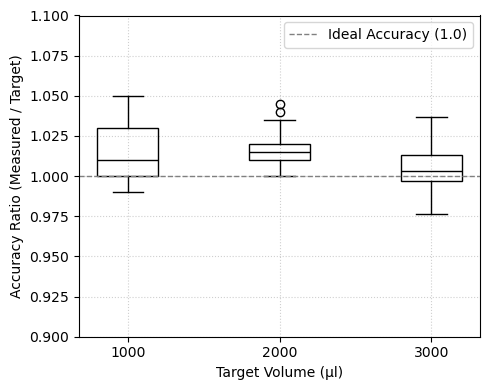

In [15]:
# Extract target volumes (in µL)
target_volumes = sorted(results_by_volume.keys())

# Convert measured values from mL to µL and compute accuracy ratios
boxplot_data = []
for vol in target_volumes:
    # Convert mL to µL
    measured_ul = np.array(results_by_volume[vol]) * 1000
    # Ratio = Measured (µL) / Target (µL)
    ratios = measured_ul / vol
    boxplot_data.append(ratios)

plt.figure(figsize=(5, 4))

bp = plt.boxplot(
    boxplot_data,
    positions=target_volumes,
    widths=np.min(np.diff(target_volumes)) * 0.4 if len(target_volumes) > 1 else 1.0,
    patch_artist=True
)

# Style all boxplot elements to black
for element in ['boxes', 'whiskers', 'caps', 'medians', 'fliers']:
    plt.setp(bp[element], color='black')

# Fill boxes with transparent black / grey outline
for box in bp['boxes']:
    box.set_facecolor('none')

# Reference line at Y = 1 (Ideal 1:1 accuracy)
plt.axhline(1.0, color='gray', linestyle='--', linewidth=1, label='Ideal Accuracy (1.0)')

plt.xlabel("Target Volume (µl)")
plt.ylabel("Accuracy Ratio (Measured / Target)")
plt.ylim([0.9, 1.1])
#plt.title("Perfusion Accuracy across Target Volumes")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

#plt.savefig("perfusion_accuracy.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

### Correct Volume Exchange

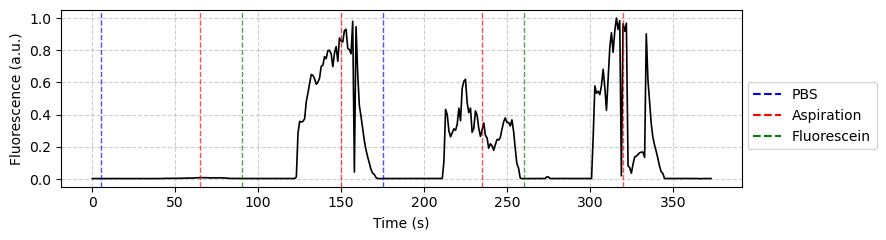

In [14]:
from matplotlib.lines import Line2D

# Load data
df = pd.read_csv("Calibration_Benchmarking/Correct_Volume_Exchange/fluorescence_time_series.csv")

full_time, full_intensity = df["Time_Frame"], df["Total_Intensity"]

# Normalize intensity
full_intensity = full_intensity / np.max(full_intensity)

# Define events: (time in seconds, event label)
events = [
    (5, "PBS"),
    (65, "Aspiration"),
    (90, "Fluorescein"),
    (150, "Aspiration"),
    (175, "PBS"),
    (235, "Aspiration"),
    (260, "Fluorescein"),
    (320, "Aspiration")
]

# Style mapping for each event type
event_styles = {
    "PBS": {"color": "blue", "linestyle": "--"},
    "Aspiration": {"color": "red", "linestyle": "--"},
    "Fluorescein": {"color": "green", "linestyle": "--"}
}

# Plot the combined fluorescence intensity over time
plt.figure(figsize=(9, 2.5)) #12.26, 3.15
plt.plot(
    full_time,
    full_intensity,
    linestyle="-",
    color="black",
    linewidth=1.2,
    label="Fluorescence"
)

# Draw vertical lines for each event
for t, label in events:
    style = event_styles[label]
    plt.axvline(
        x=t,
        color=style["color"],
        linestyle=style["linestyle"],
        alpha=0.7,
        linewidth=1.0
    )

# Create a clean legend without duplicate labels
legend_elements = [
    Line2D([0], [0], color="blue", linestyle="--", label="PBS"),
    Line2D([0], [0], color="red", linestyle="--", label="Aspiration"),
    Line2D([0], [0], color="green", linestyle="--", label="Fluorescein"),
]

plt.xlabel("Time (s)")
plt.ylabel("Fluorescence (a.u.)")
plt.grid(True, linestyle="--", alpha=0.6)

plt.legend(handles=legend_elements, bbox_to_anchor=(1.2, .6), borderaxespad=0.1)

plt.tight_layout()
plt.savefig("fluorescence.png", dpi=300, bbox_inches='tight')
plt.show()